<div style="border-left:5px solid #67CBEE;padding:10px 16px;background:#F7F9FB;color:#19222D;margin:12px 0"><b>AMD Radeon · YOLO26 · Day 01</b><br><span style="color:#536273">算法 → 数据 → 训练 → 评测 → 证据。每一个结论都应由实际运行结果支撑。</span><br><span style="color:#536273">Algorithm → Data → Training → Evaluation → Evidence. Every conclusion must be backed by real execution results.</span></div>

# 04 / Lab D · mAP、混淆与失败案例

**建议时长：35–45 分钟**　｜　学习路径：35–45 minutes

> 请按顺序运行；运行结果必须来自自己的 GPU 环境，不可把示例文字当作实测数据。

---

# 04 / Lab D · mAP, Confusion & Failure Cases

**Suggested time: 官方指标 → 固定阈值配对 → 错误归因** | Learning path: official metrics → fixed-threshold matching → error attribution

> Run the cells in order; every result must come from your own GPU environment — never present the sample text as measured data.

## 实验目标
- 用 Ultralytics 官方验证器计算 Precision、Recall、mAP50、mAP50-95。
- 独立完成一次**固定 `conf=0.25`、IoU=0.50 的教学级 TP/FP/FN 匹配**（并非 COCO mAP 实现）。
- 查看 PR/混淆矩阵并生成至少五份真实失败案例。
- 不用 Test 集选择模型或调阈值。

`metrics.box.map` 才是官方 mAP50-95；我们的 TP/FP/FN 固定阈值分析只用于学习错误原因。

---

## Goal
- Compute Precision, Recall, mAP50 and mAP50-95 with the official Ultralytics validator.
- Independently run a **fixed-threshold `conf=0.25`, IoU=0.50 teaching-level TP/FP/FN matching** (this is NOT the COCO mAP algorithm).
- Inspect PR/confusion matrices and produce at least five genuine failure cases.
- Never use the test split to pick models or tune thresholds.

`metrics.box.map` is the official mAP50-95; our fixed-threshold TP/FP/FN analysis exists only to learn about error causes.

In [1]:
from pathlib import Path
import os, sys, json
candidates = [Path.cwd(), Path.cwd().parent, Path('/workspace/YOLO26_ROCm_Day1_Labs')]
package = next((p for p in candidates if (p/'course/lab_utils.py').exists()), None)
if package is None:
    raise FileNotFoundError('请先将 ZIP 完整解压，并从项目目录或 notebooks/ 目录启动 Jupyter。')
sys.path.insert(0, str(package))
from course.lab_utils import (root, ensure_dirs, load_config, save_config, write_json,
    write_csv, system_info, require_rocm, sha256)
home = ensure_dirs()
cfg = load_config()
print('Project:', package, '\nPersistent output:', home)

Project: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs 
Persistent output: C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check


In [2]:
from course.lab_utils import (get_metrics_summary, inspect_dataset, match_predictions,
                                  xywhn_to_xyxy, read_labels, label_path_for_image)
from ultralytics import YOLO
from PIL import Image,ImageDraw
from IPython.display import display
import torch
device=require_rocm()
assert cfg['baseline_weights'] and Path(cfg['baseline_weights']).is_file(), '先完成 Lab C，或经过核验设置 best.pt'
assert Path(cfg['dataset_yaml']).is_file()
model=YOLO(cfg['baseline_weights'])
print('Weight SHA256:',sha256(Path(cfg['baseline_weights'])))

AMD ROCm verified: AMD Radeon RX 7900 XTX HIP: 7.14.60850
Weight SHA256: 97ed485c23ee4b348d81c3aafb43468c11ddb538cd1c75f03372fb4b50818e5f


In [3]:
# 正式官方 mAP 计算：不要把 conf=0.25 当作计算 mAP 的唯一阈值
val_metrics=model.val(data=cfg['dataset_yaml'],split='val',device=device,
                      imgsz=640,batch=8,workers=0,plots=True,verbose=False)
score=get_metrics_summary(val_metrics)
score.update({'split':'val','dataset_yaml':cfg['dataset_yaml'],
              'weight_sha256':sha256(Path(cfg['baseline_weights']))})
write_json(home/'reports/lab_d_official_metrics.json',score)
print('Official validation metrics:',score)
print('mAP: IoU=0.50..0.95 average, NOT confidence 50%-95%')

Ultralytics 8.4.198  Python-3.12.16 torch-2.12.0+rocm7.14.1 CUDA:0 (AMD Radeon RX 7900 XTX, 24560MiB)


YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs


val: Fast image access  (ping: 0.0±0.0 ms, read: 991.2±239.2 MB/s, size: 44.3 KB)


val: Scanning C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\data\processed\coco128_classroom_3class\labels\val.cache... 20 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 20/20  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 33% ━━━━──────── 1/3 1.7it/s 0.2s<1.2s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 9.3it/s 0.3s

                   all         20         29      0.838      0.552      0.624       0.38


Speed: 0.4ms preprocess, 6.9ms inference, 0.0ms loss, 0.6ms postprocess per image


Results saved to C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\runs\detect\val-6


Official validation metrics: {'precision': 0.8380172396172074, 'recall': 0.5517241379310345, 'mAP50': 0.6244846379177516, 'mAP50_95': 0.37951232443540484, 'split': 'val', 'dataset_yaml': 'C:\\Users\\Rocm\\Desktop\\YOLO\\YOLO26_ROCm_Day1_Labs\\yolo_course_bilingual_check\\data\\processed\\coco128_classroom_3class\\data.yaml', 'weight_sha256': '97ed485c23ee4b348d81c3aafb43468c11ddb538cd1c75f03372fb4b50818e5f'}
mAP: IoU=0.50..0.95 average, NOT confidence 50%-95%


BoxPR_curve.png


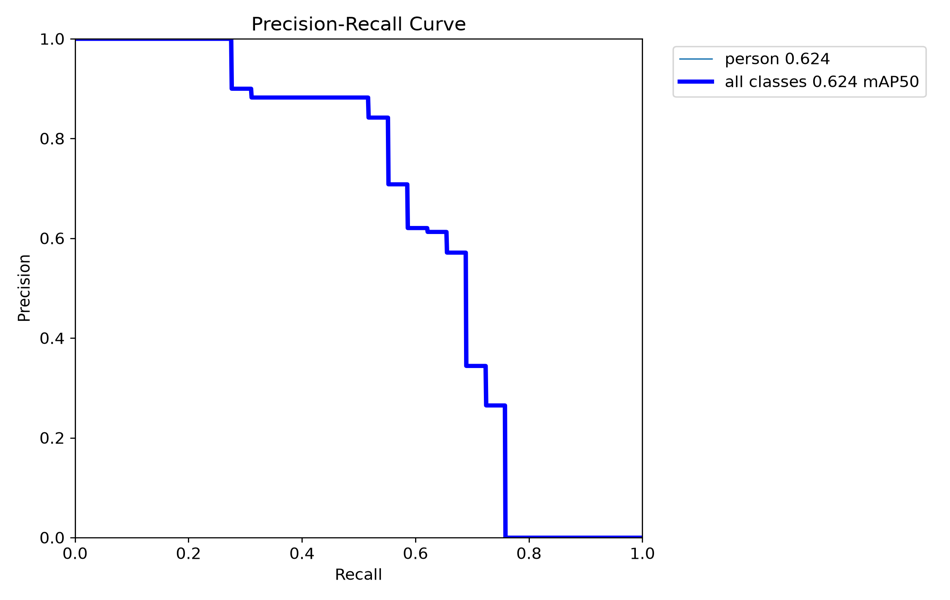

confusion_matrix.png


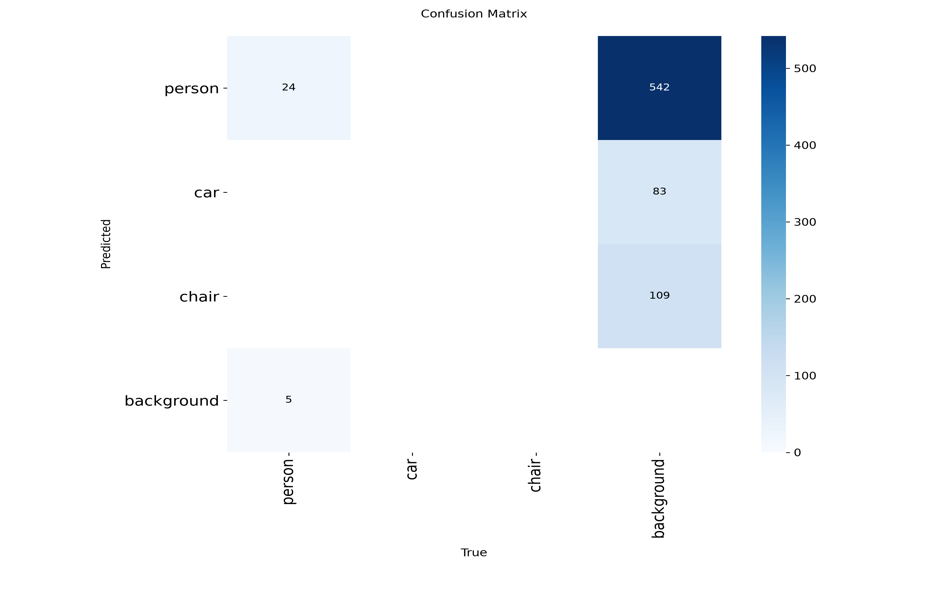

confusion_matrix_normalized.png


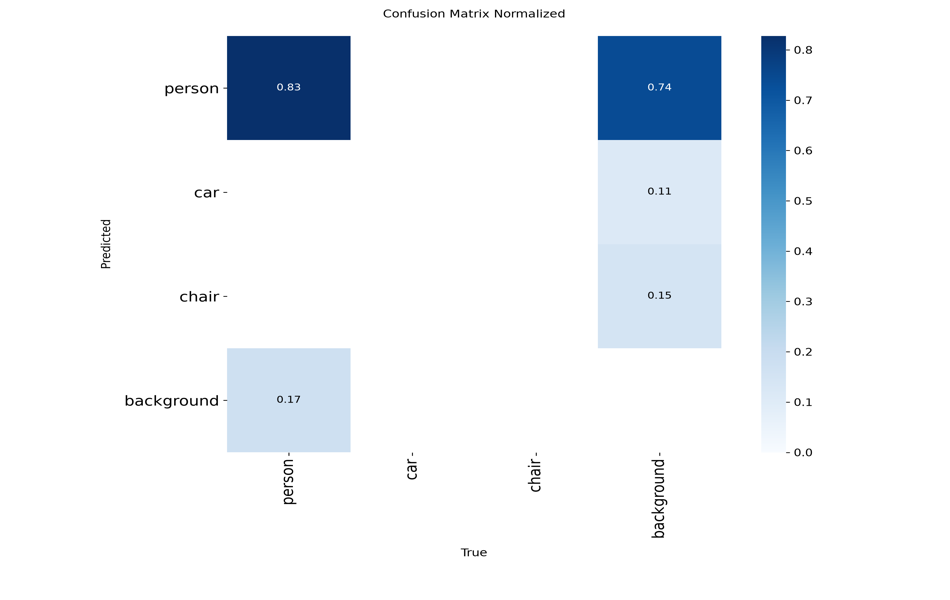

In [4]:
# 展示 Ultralytics 官方可视化（如果已生成）
from PIL import Image
out=Path(val_metrics.save_dir)
for title in ('BoxPR_curve.png','PR_curve.png','confusion_matrix.png','confusion_matrix_normalized.png'):
    p=out/title
    if p.exists():
        print(title)
        display(Image.open(p).resize((950,600)))

In [5]:
# 手工逐图片匹配：一个 GT 最多配一个同类、IoU>=0.50 的预测，其他为 FP/FN
qa=inspect_dataset(Path(cfg['dataset_yaml']))
val_images=qa['sample_paths']['val']
rows=[]; failures=[];totals={'TP':0,'FP':0,'FN':0}
for img in val_images:
    pred=model.predict(source=str(img),device=device,imgsz=640,
                       conf=0.25,iou=0.70,verbose=False)[0]
    gt=label_path_for_image(img)
    match=match_predictions(pred,gt,iou_threshold=0.50)
    for k in totals:totals[k]+=match[k]
    for issue in match['errors']:
        rows.append({'image':img.name,'image_path':str(img),'error':issue['error'],
                     'class_id':issue['class_id'],'score':issue['score'],'max_iou_gt':issue['max_iou_gt']})
    if match['errors']:
        failures.append((img,pred,gt,match))
precision=totals['TP']/max(1,totals['TP']+totals['FP'])
recall=totals['TP']/max(1,totals['TP']+totals['FN'])
print('Fixed threshold teaching-level counts:',totals, 'P:',round(precision,3),'R:',round(recall,3))
print('Important: these are NOT the official integrated PR or mAP values.')
write_csv(home/'reports/lab_d_errors.csv',rows,
          ['image','image_path','error','class_id','score','max_iou_gt'])
write_json(home/'reports/lab_d_fixed_threshold.json',{'conf':0.25,'matching_iou':0.50,
 'nms_iou':0.70,'counts':totals,'precision_fixed':precision,'recall_fixed':recall,
 'note':'Teaching matching only; not a COCO AP implementation.'})

Fixed threshold teaching-level counts: {'TP': 18, 'FP': 6, 'FN': 11} P: 0.75 R: 0.621
Important: these are NOT the official integrated PR or mAP values.


C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\assets\lab_d_errors\01_000000000074.jpg errors: 3


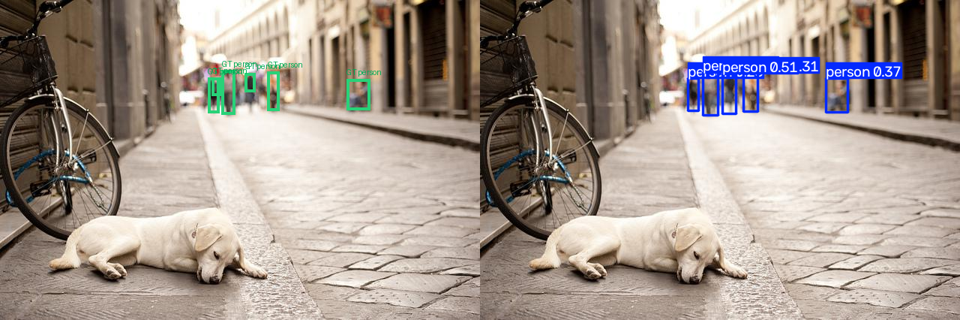

C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\assets\lab_d_errors\02_000000000241.jpg errors: 3


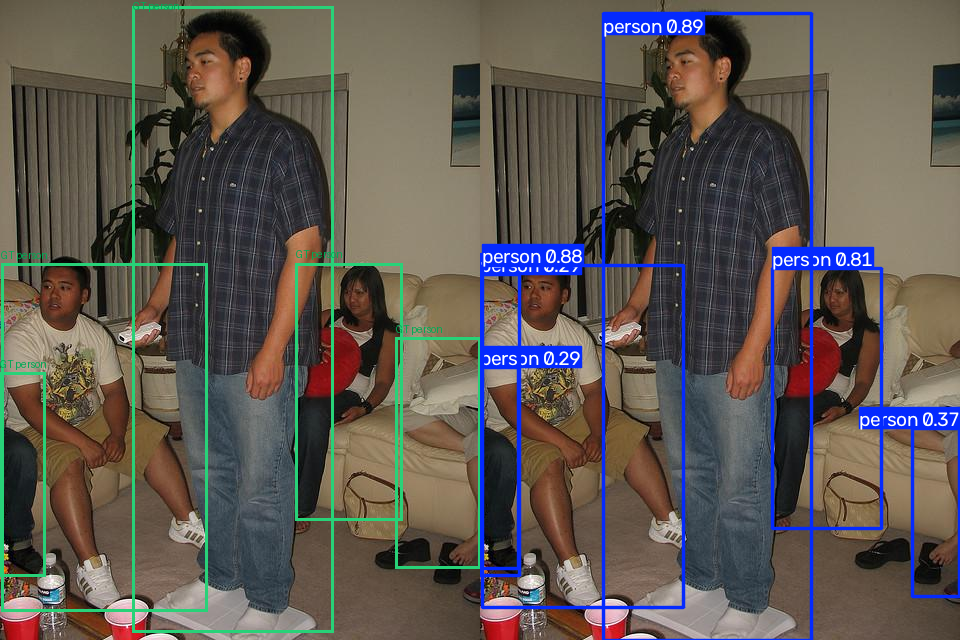

C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\assets\lab_d_errors\03_000000000520.jpg errors: 3


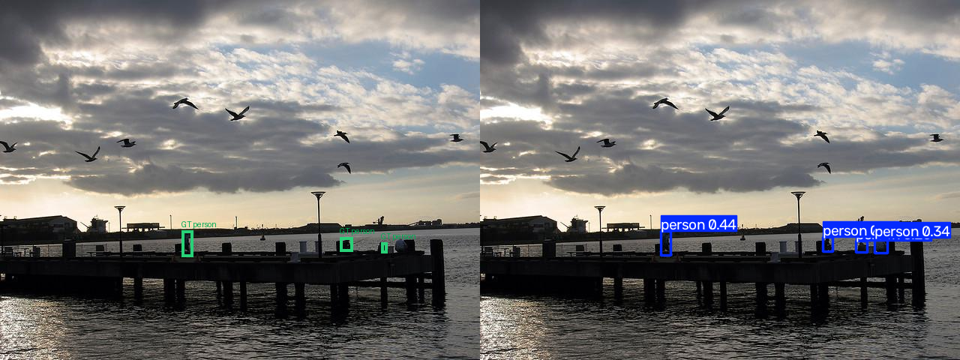

C:\Users\Rocm\Desktop\YOLO\YOLO26_ROCm_Day1_Labs\yolo_course_bilingual_check\assets\lab_d_errors\04_000000000641.jpg errors: 8


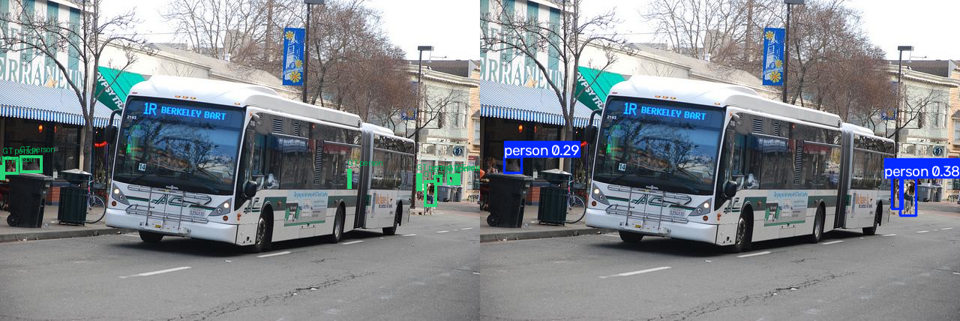

只有 4 张有失败案例。不能编造；可拓展验证集或评估更多困难样本。


In [6]:
# 保存真实失败图（左真值，右预测）；如果几乎无错误，忠实报告而不是捏造 5 个。
from PIL import Image,ImageDraw
error_dir=home/'assets/lab_d_errors';error_dir.mkdir(parents=True,exist_ok=True)
names=list(qa['names'].values()) if isinstance(qa['names'],dict) else list(qa['names'])
for idx,(img,pred,lab,match) in enumerate(failures[:5],1):
    gt=Image.open(img).convert('RGB')
    W,H=gt.size; d=ImageDraw.Draw(gt)
    for box in read_labels(lab):
        coords=xywhn_to_xyxy(box,W,H)
        d.rectangle(coords,outline=(40,210,120),width=max(2,W//160))
        d.text((coords[0],max(0,coords[1]-15)),f'GT {names[box[0]]}',fill=(0,170,85))
    predicted=Image.fromarray(pred.plot()[...,::-1]).convert('RGB')
    board=Image.new('RGB',(W*2,H),(245,248,250));board.paste(gt,(0,0));board.paste(predicted,(W,0))
    p=error_dir/f'{idx:02d}_{img.stem}.jpg';board.save(p,quality=90)
    print(p,'errors:',len(match['errors']))
    display(board.resize((960,round(960*H/(2*W)))))
if len(failures)<5:
    print(f'只有 {len(failures)} 张有失败案例。不能编造；可拓展验证集或评估更多困难样本。')

### 学生工作：手动归因至少 5 个实际错误（如果有）
打开 `reports/lab_d_errors.csv` 和并排对照图，添加 **现象、证据、可能根因、下次实验验证方法**。把推测与已确认根因区分开。

### 思考题 / 面试必答
1. 为什么官方 mAP50 和单一 conf=0.25 下的 Precision 不是同一个东西？
2. IoU=0.5 的定位标准会漏掉什么信息？
3. `mAP50-95` 的 50–95 指置信度吗？
4. 为什么不能用测试集调阈值后再报告该测试集成绩？

**交付**：`lab_d_official_metrics.json`、`lab_d_fixed_threshold.json`、`lab_d_errors.csv`、至少现有真实失败图和分析报告。

---

### Student Work: manually attribute at least 5 real errors (if any)
Open `reports/lab_d_errors.csv` and the side-by-side boards, then add **symptom, evidence, suspected root cause, and how the next experiment would verify it**. Keep hypotheses clearly separate from confirmed causes.

### Think / Interview Questions
1. Why is the official mAP50 not the same thing as Precision at a single conf=0.25?
2. What information does an IoU=0.5 localization criterion throw away?
3. Does the 50–95 in `mAP50-95` refer to confidence?
4. Why can't you tune thresholds on a test set and then report scores on that same set?

**Deliverables**: `lab_d_official_metrics.json`, `lab_d_fixed_threshold.json`, `lab_d_errors.csv`, the real failure images so far and an analysis report.